#### The travelling Whitham wave 

In this notebook a travelling wave profile is created and then solved forward in time

In [1]:
import sys
from pathlib import Path

root = Path.cwd().parent.parent
sys.path.insert(0,str(root))

In [2]:
from solvers.spectral import WhithamNewton
from solvers.pde import Whitham
from solvers.lsm import LSM
from solvers.help import *

import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt


In [3]:
P           = 4* np.pi
target_amp  = 0.2
mean        = 0

N           = 2**6

In [4]:
twave = WhithamNewton(P=P, target_amp=target_amp, mean= mean, N = N)
twave.solve_w_continuation(n_steps=50)

amplitude = 0.31172765314111617
Wave speed c = 1.048062634620725
Constant B = 0.015010843231035438


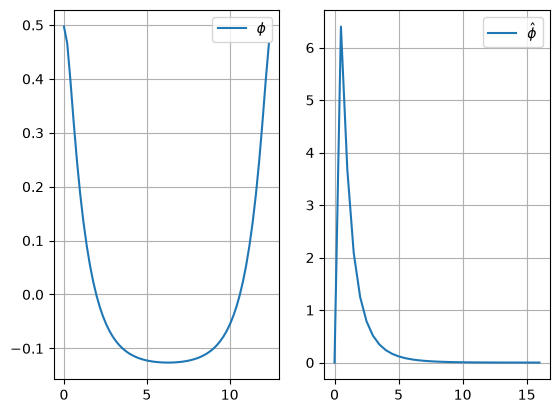

In [5]:
twave._plot_()

### Then solving it forward in time

In [6]:
dt  = 5e-3
T   = 3
#As the Spectral solver workes only on the positive part of the spectrum due to symmetry
u0 = np.fft.irfft(twave.phi_hat)

fwave = Whitham(P=P, dt =dt , T=T, u0=u0 )
t, u = fwave.splitStep()


In [7]:
x = np.linspace(0,P,N)
animate_solution_nb(x,u, stride=2)